# EDA: Exploratory Data Analysis (training set only)

**Input:** `train.csv`. The held-out test period is **never loaded here**, so nothing in this notebook can leak it into feature or modelling decisions.

**Plan**
1. Target analysis: price distribution, skew, log transform, price over time, seasonality
2. Univariate distributions of the features
3. Feature vs. price relationships (correlations, group medians, scatter/hexbin)
4. Drift inside train: early vs. late period
5. Leakage check (why the excluded columns are excluded)
6. A naive baseline to beat
7. Decisions for Preprocessing

In [1]:
#pip install scikit-learn

In [2]:
# Load libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from sklearn.model_selection import train_test_split
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

In [3]:
DATA_PATH = "train_data.csv"
TARGET = "ClosePrice"
DATE_COL = "CloseDate"

df = pd.read_csv(DATA_PATH, low_memory=False)

required_cols = {TARGET, DATE_COL}
missing_required = required_cols - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing from {DATA_PATH}: {sorted(missing_required)}")

print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
display(df.head())
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

Rows: 297,224 | Columns: 84


,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,BuyerAgencyCompensationType,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,BuyerAgencyCompensation,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,latfilled,lonfilled,BuyerAgentAOR,ListAgentAOR,OriginatingSystemName,OriginatingSystemSubName
0,NaN,False,NaN,NaN,False,759900.0,522107581,mdarwich12@gmail.com,2024-01-05,815000.0,Michael,Darwich,32.659315,-117.096922,2811 C Avenue,Residential,1974.0,759900.0,33,Berkshire Hathaway HomeServices California Pro...,FOSTER HAMILTON Real Estate,NaN,Michael Darwich,NaN,NaN,SAND-606727,Charles,Street,NaN,NaN,NaN,522107581,91950 - National City,NaN,San Diego,Closed,NaN,True,2.0,NaN,SingleFamilyResidence,NaN,National City,SanDiego,2023.0,Item1,2811.0,210014555,4.0,National City,2.0,NaN,NaN,4,2024-01-05,NaN,NaN,2021-06-30,2021-03-08,NaN,NaN,CA,NaN,NaN,False,2.0,NaN,Two,NaN,NaN,NaN,False,2.0,NaN,91950,NaN,NaN,NaN,True,True,NaN,NaN,NaN,NaN
1,NaN,False,NaN,NaN,False,739900.0,510919001,mdarwich12@gmail.com,2024-01-05,810000.0,Michael,Darwich,32.659284,-117.097174,2812 C Avenue,Residential,1974.0,770000.0,228,Berkshire Hathaway HomeServices California Pro...,FOSTER HAMILTON Real Estate,NaN,Michael Darwich,NaN,NaN,SAND-606727,Charles,Street,NaN,NaN,NaN,510919001,91950 - National City,NaN,San Diego,Closed,NaN,True,2.0,NaN,SingleFamilyResidence,NaN,National City,SanDiego,2023.0,Item1,2812.0,210008330,4.0,National City,2.0,NaN,NaN,4,2024-01-05,NaN,NaN,2021-11-18,2021-03-08,NaN,NaN,CA,NaN,NaN,False,2.0,NaN,Two,NaN,NaN,NaN,False,2.0,NaN,91950,NaN,NaN,NaN,True,True,NaN,NaN,NaN,NaN
2,NaN,True,NaN,NaN,False,2100000.0,1067652762,jenniferarielkennedy@gmail.com,2024-01-02,2100000.0,Jennifer,Kennedy,35.277199,-120.646786,2054 Fixlini Street,Residential,3736.0,2100000.0,0,Home & Ranch Sotheby's Intl,Home & Ranch Sotheby's Intl,NaN,Jennifer Kennedy,NaN,NaN,NS02093802,Jennifer,Kennedy,NaN,NaN,NaN,1067652762,SLO - San Luis Obispo,NaN,San Luis Obispo,Closed,NaN,True,3.0,NaN,SingleFamilyResidence,0.2576,San Luis Obispo(380),NorthSanLuisObispo,2019.0,Item1,2054.0,NS24001417,4.0,San Luis Obispo,3.0,NaN,NaN,4,2024-01-02,NaN,NaN,2023-11-15,2023-11-15,NaN,NaN,CA,NaN,NaN,True,2.0,NaN,Two,NaN,11219.00,3.0,False,3.0,San Luis Coastal Unified,93401,0.0,11219.0,NaN,False,False,NaN,NaN,NaN,NaN
3,Tile,True,NaN,NaN,False,1950000.0,1063453216,kira@mendosir.com,2024-01-22,1950000.0,Kira,Meade,39.419080,-123.814842,31451 Bay View Avenue,Residential,2100.0,1950000.0,-36,Mendo Sotheby's International Realty,West Coast Property Management and Sales,NaN,Kira Meade,NaN,NaN,VCR-cmdeedeethomas,DeeDee,Thomas,NaN,NaN,NaN,1063453216,FBS - Fort Bragg South,NaN,Mendocino,Closed,NaN,True,2.0,NaN,SingleFamilyResidence,1.7100,NaN,CoastalMendocino,1986.0,Item1,31451.0,C1-10456,0.0,Fort Bragg,2.5,NaN,NaN,3,2024-01-22,NaN,NaN,2023-12-19,2023-11-17,NaN,NaN,CA,NaN,NaN,True,2.0,NaN,Two,NaN,1.71,NaN,NaN,2.0,NaN,95437,NaN,74487.6,NaN,False,False,NaN,NaN,NaN,NaN
4,"Tile,Wood",True,NaN,NaN,NaN,NaN,10619

,column_count
dtype,
str,43
float64,28
object,9
int64,4


In [4]:
keep = ['ViewYN', 'PoolPrivateYN', 'OriginalListPrice', 
       'CloseDate', 'ClosePrice', 'Latitude', 'Longitude',  'LivingArea', 
       'LotSizeAcres', 'YearBuilt', 'BathroomsTotalInteger', 'City',
       'BedroomsTotal', 'ContractStatusChangeDate', 'PurchaseContractDate',
       'ListingContractDate', 'FireplaceYN', 'LotSizeArea', 'NewConstructionYN', 
       'GarageSpaces', 'PostalCode', 'LotSizeSquareFeet', 'ListPrice', 'DaysOnMarket']

# columns to drop
# ['ListingKey', 'ListAgentEmail', 'ListAgentFirstName', 'ListAgentLastName', 'UnparsedAddress',
#       'PropertyType', 'ListOfficeName', 'BuyerOfficeName', 'ListAgentFullName',
#        'BuyerAgentMlsId', 'BuyerAgentFirstName', 'BuyerAgentLastName',
#        'ListingKeyNumeric', 'CountyOrParish', 'MlsStatus', 'ParkingTotal',
#        'StreetNumberNumeric', 'ListingId', 'PropertySubType',  'StateOrProvince',
#        'BuyerOfficeAOR', 'Levels']

#drop = [col for col in df.columns if col not in keep]
#df = df.drop(columns=drop)

In [5]:
date_cols = [
    c for c in [
        "CloseDate", "ContractStatusChangeDate", "PurchaseContractDate",
        "ListingContractDate"
    ] if c in df.columns
]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Exact duplicate rows:", int(df.duplicated().sum()))
print(f"Missing {DATE_COL}:", int(df[DATE_COL].isna().sum()))
print(f"Missing {TARGET}:", int(df[TARGET].isna().sum()))

if pd.api.types.is_numeric_dtype(df[TARGET]):
    print("Non-positive target values:", int((df[TARGET] <= 0).sum()))
else:
    df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
    print("Non-positive or invalid target values:", int((df[TARGET] <= 0).sum()))

missing_summary = (
    df.isna().mean().mul(100).sort_values(ascending=False)
      .rename("pct_missing").to_frame()
)
display(missing_summary.head(30).round(1))

Exact duplicate rows: 29
Missing CloseDate: 0
Missing ClosePrice: 2
Non-positive target values: 1


,pct_missing
TaxYear,100.0
FireplacesTotal,100.0
TaxAnnualAmount,100.0
AboveGradeFinishedArea,100.0
ElementarySchoolDistrict,100.0
BusinessType,100.0
CoveredSpaces,100.0
MiddleOrJuniorSchoolDistrict,100.0
WaterfrontYN,100.0
BelowGradeFinishedArea,99.4


In [6]:
df.describe(include="all").T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,max
Flooring,191068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ViewYN,270723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WaterfrontYN,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BasementYN,7147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PoolPrivateYN,268468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OriginalListPrice,296649.0,1345231.384404,7147899.250369,0.0,629195.0,899000.0,1429000.0,1390000000.0
ListingKey,297224.0,1096069973.190375,29923216.304686,421678487.0,1075123441.0,1095103623.5,1116062159.25,1156815844.0
ListAgentEmail,296512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CloseDate,297224,2025-02-06 01:06:54.426830,NaN,2024-01-01 00:00:00,2024-07-15 00:00:00,2025-02-07 00:00:00,2025-08-25 00:00:00,2026-03-31 00:00:00
ClosePrice,297222.0,1289670.555324,5252200.528101,0.0,625000.0,890000.0,1430000.0,989500000.0


# Rows without a valid close date or target cannot be used for this supervised,
# close-price/time-based analysis. Preserve df unchanged for separate data-quality work.
analysis_df = df.dropna(subset=[DATE_COL, TARGET]).copy()
analysis_df = analysis_df.loc[np.isfinite(analysis_df[TARGET])].copy()
analysis_df = analysis_df.sort_values(DATE_COL).reset_index(drop=True)

if analysis_df.empty:
    raise ValueError("No rows remain after requiring valid CloseDate and ClosePrice.")
if (analysis_df[TARGET] <= 0).any():
    print("Warning: non-positive ClosePrice values remain; inspect before log analysis.")

cutoff = analysis_df[DATE_COL].max() - pd.DateOffset(months=6)
train = analysis_df.loc[analysis_df[DATE_COL] < cutoff].copy().reset_index(drop=True)
test = analysis_df.loc[analysis_df[DATE_COL] >= cutoff].copy().reset_index(drop=True)

if train.empty or test.empty:
    raise ValueError(
        "The six-month split produced an empty train or test set. "
        "Check the date range and the number of observations."
    )

print(f"Cutoff: {cutoff}")
print(f"Train: {len(train):,} rows | {train[DATE_COL].min()} to {train[DATE_COL].max()}")
print(f"Test:  {len(test):,} rows | {test[DATE_COL].min()} to {test[DATE_COL].max()}")
display(train.describe(include="all").T.head(30))

count       297222.0
mean       1289671.0
std        5252201.0
min              0.0
0.5%        190000.0
25%         625000.0
50%         890000.0
75%        1430000.0
99.5%      8400000.0
max      989500000.0
Invalid/non-positive training prices: 3
skew(price) = 142.43
skew(log1p(price)) = 0.47


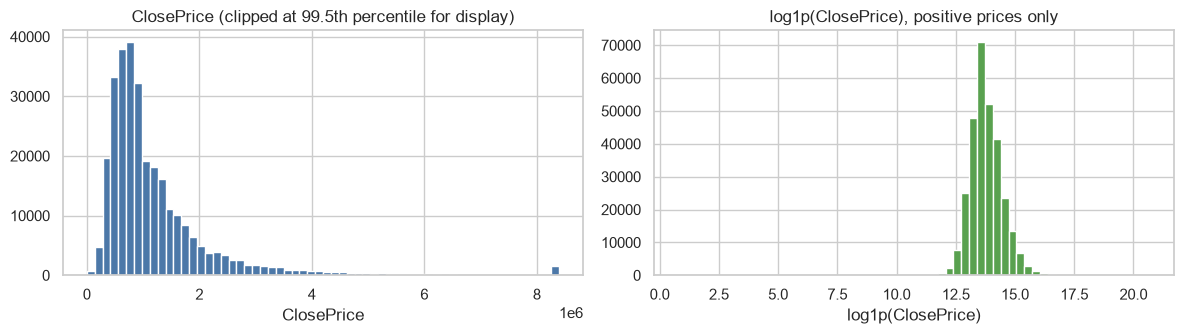

In [8]:
price = pd.to_numeric(df[TARGET], errors="coerce")
valid_price = price[np.isfinite(price) & (price > 0)]
log_price = np.log1p(valid_price)

print(df[TARGET].describe(percentiles=[.005, .25, .5, .75, .995]).round(0).to_string())
print(f"Invalid/non-positive training prices: {(~(np.isfinite(price) & (price > 0))).sum():,}")
print(f"skew(price) = {stats.skew(valid_price):.2f}")
print(f"skew(log1p(price)) = {stats.skew(log_price):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
upper = valid_price.quantile(.995)
axes[0].hist(valid_price.clip(upper=upper), bins=60, color="#4c78a8")
axes[0].set_title("ClosePrice (clipped at 99.5th percentile for display)")
axes[0].set_xlabel("ClosePrice")
axes[1].hist(log_price, bins=60, color="#59a14f")
axes[1].set_title("log1p(ClosePrice), positive prices only")
axes[1].set_xlabel("log1p(ClosePrice)")
plt.tight_layout()
plt.show()

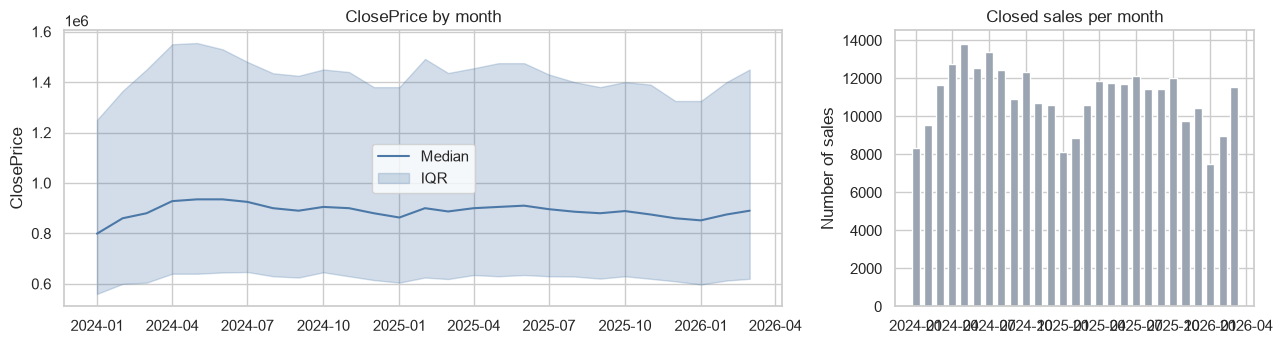

,n,median,q25,q75
month,,,,
2024-01,8321,799000.0,560000.00,1250000.0
2024-02,9564,860000.0,599900.00,1365000.0
2024-03,11633,880000.0,604679.00,1450000.0
2024-04,12743,928000.0,640000.00,1550000.0
2024-05,13829,935000.0,639999.00,1555000.0
2024-06,12544,935000.0,645000.00,1530000.0
2024-07,13376,925000.0,646915.25,1480000.0
2024-08,12431,900000.0,630000.00,1435000.0
2024-09,10908,890000.0,625000.00,1425000.0


In [9]:
monthly_data = df.dropna(subset=[DATE_COL, TARGET]).copy()
monthly_data["month"] = monthly_data[DATE_COL].dt.to_period("M")
monthly = monthly_data.groupby("month")[TARGET].agg(
    n="size",
    median="median",
    q25=lambda s: s.quantile(.25),
    q75=lambda s: s.quantile(.75),
)
x = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(x, monthly["median"], color="#4c78a8", label="Median")
axes[0].fill_between(x, monthly["q25"], monthly["q75"], alpha=.25, color="#4c78a8", label="IQR")
axes[0].set_title("ClosePrice by month")
axes[0].set_ylabel("ClosePrice")
axes[0].legend()
axes[1].bar(x, monthly["n"], width=20, color="#9aa5b1")
axes[1].set_title("Closed sales per month")
axes[1].set_ylabel("Number of sales")
plt.tight_layout()
plt.show()

display(monthly)

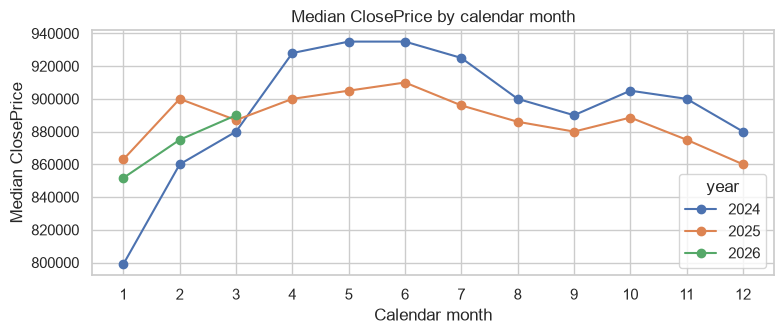

In [10]:
seasonal_data = df.dropna(subset=[DATE_COL, TARGET]).copy()
seasonal_data["year"] = seasonal_data[DATE_COL].dt.year
seasonal_data["calendar_month"] = seasonal_data[DATE_COL].dt.month
seasonality = (
    seasonal_data.groupby(["year", "calendar_month"])[TARGET]
    .median()
    .unstack("year")
)

ax = seasonality.plot(figsize=(8, 3.5), marker="o", title="Median ClosePrice by calendar month")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Median ClosePrice")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

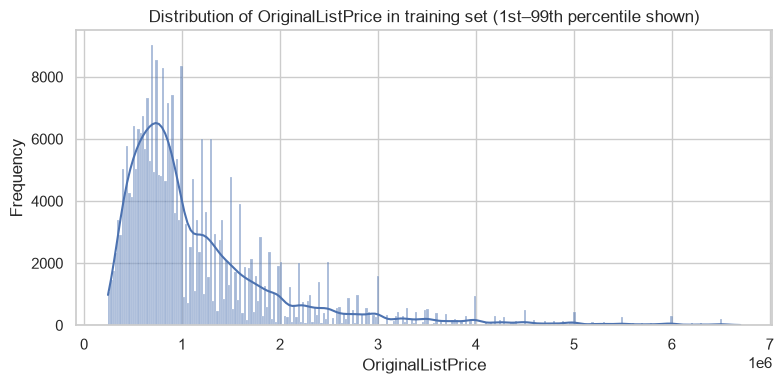

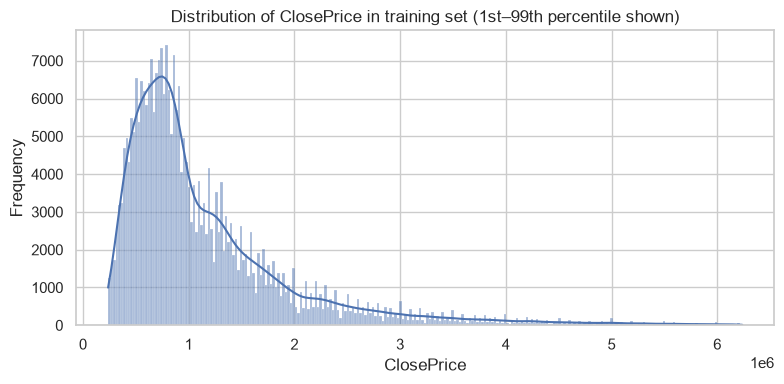

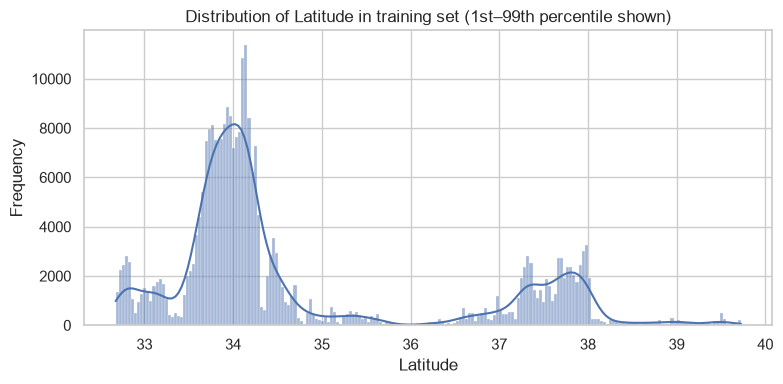

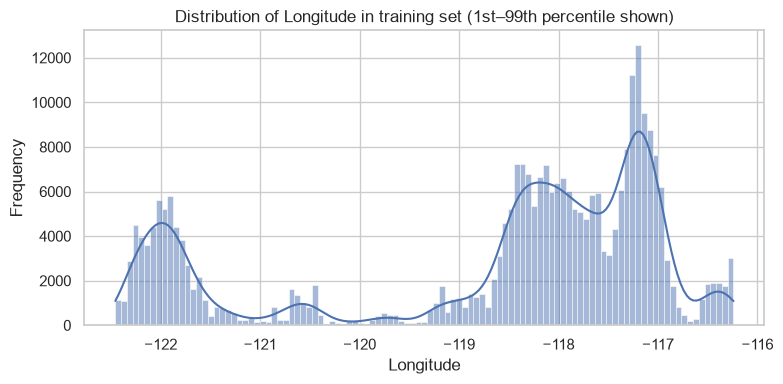

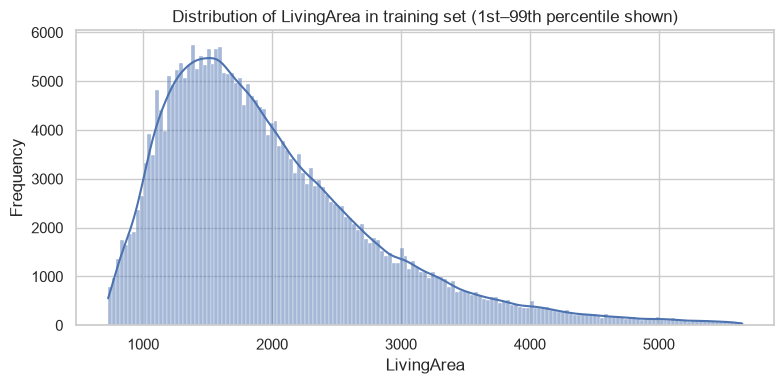

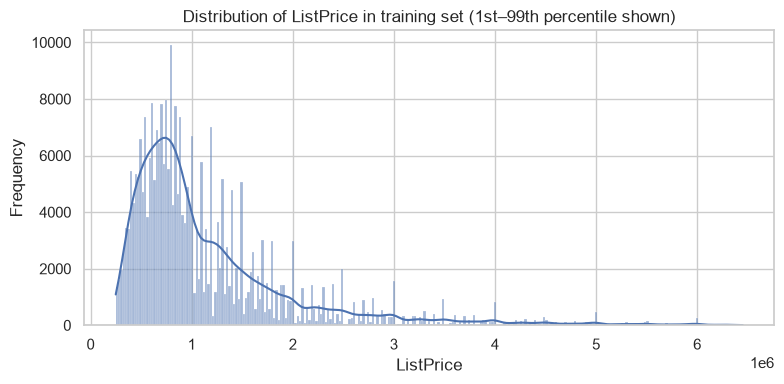

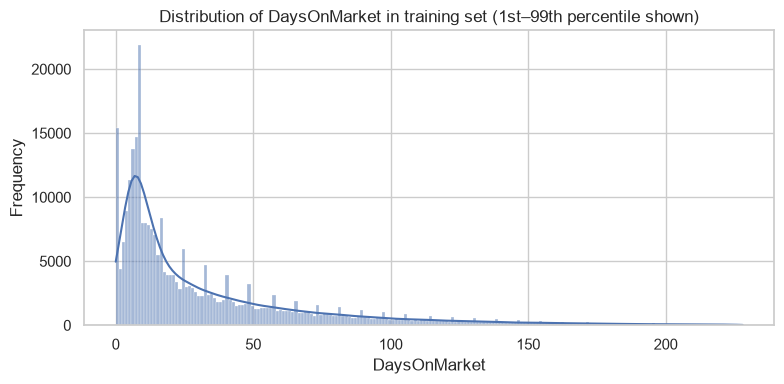

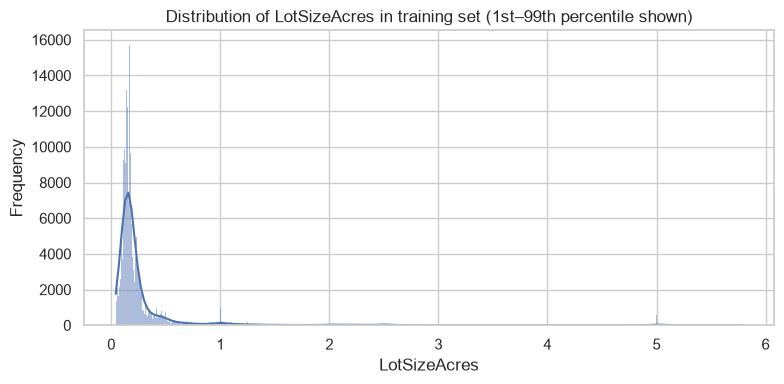

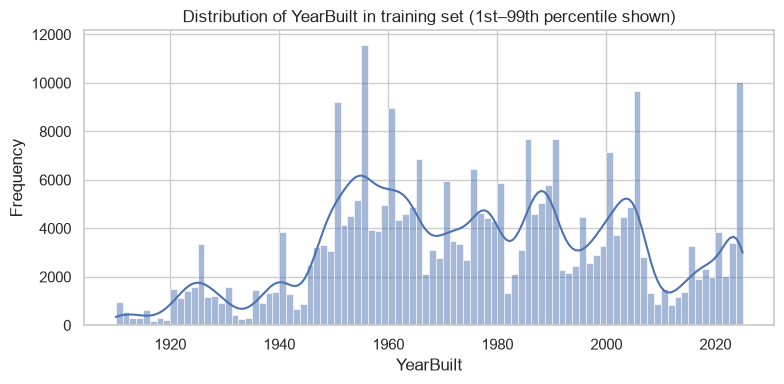

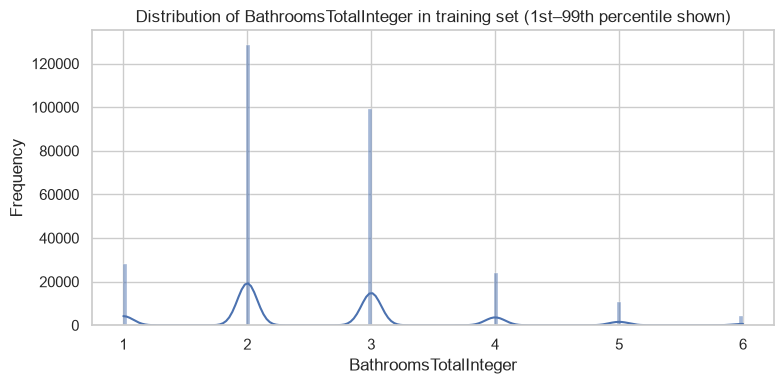

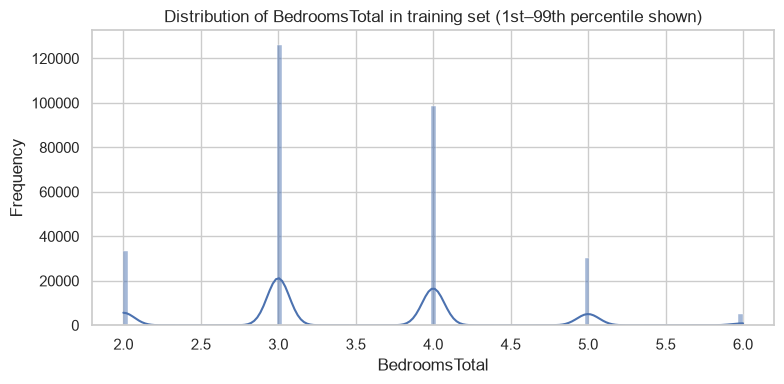

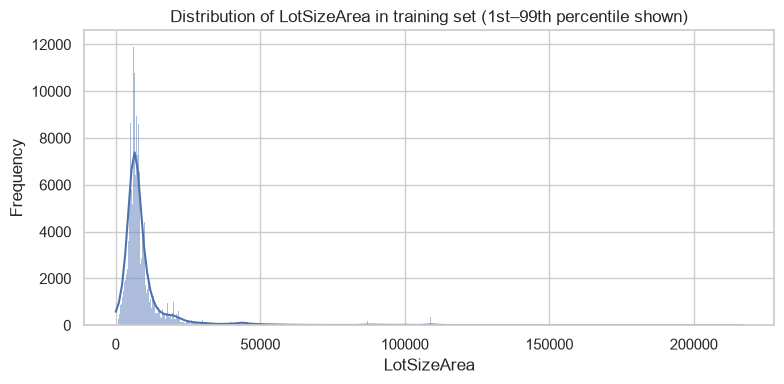

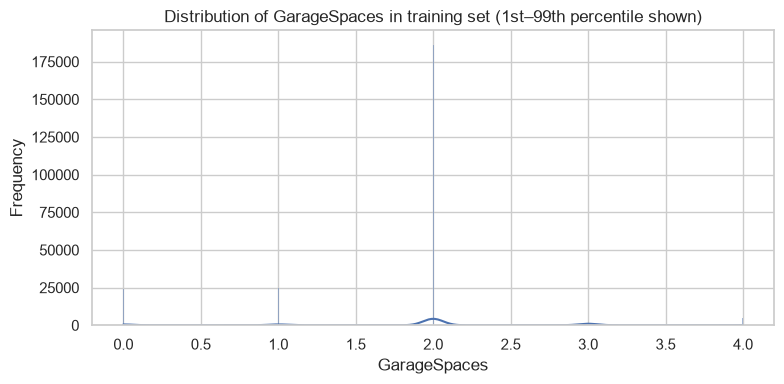

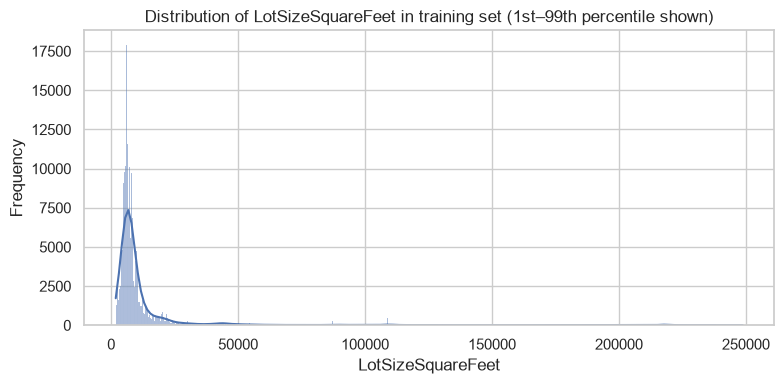

In [11]:
distribution_candidates = [
    "OriginalListPrice", "ClosePrice", "Latitude", "Longitude", "LivingArea",
    "ListPrice", "DaysOnMarket", "LotSizeAcres", "YearBuilt",
    "BathroomsTotalInteger", "BedroomsTotal", "LotSizeArea", "GarageSpaces",
    "LotSizeSquareFeet"
]
describe_list = [
    c for c in distribution_candidates
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]

if not describe_list:
    print("No candidate numeric columns were found.")
else:
    quantiles = df[describe_list].quantile([0.01, 0.99])
    for col in describe_list:
        values = df[col].dropna()
        values = values[values.between(quantiles.loc[0.01, col], quantiles.loc[0.99, col])]
        if values.empty:
            print(f"Skipping {col}: no values after display-only percentile filtering.")
            continue
        plt.figure(figsize=(8, 4))
        sns.histplot(x=values, bins="auto", kde=len(values) > 1)
        plt.title(f"Distribution of {col} in training set (1st–99th percentile shown)")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

In [12]:
# Add this to Preprocessing pipeline
numeric_cols = [
    c for c in df.columns
    if pd.api.types.is_numeric_dtype(df[c]) and c != TARGET
]
if numeric_cols:
    tails = df[numeric_cols].describe(
        percentiles=[.001, .01, .5, .99, .999]
    ).T
    display(tails[["count", "min", "0.1%", "1%", "50%", "99%", "99.9%", "max"]].round(2))
else:
    print("No numeric feature columns found.")

,count,min,0.1%,1%,50%,99%,99.9%,max
OriginalListPrice,296649.0,0.000000e+00,6.500000e+04,2.450000e+05,8.990000e+05,6.700000e+06,1.999606e+07,1.390000e+09
ListingKey,297224.0,4.216785e+08,1.033525e+09,1.044697e+09,1.095104e+09,1.152874e+09,1.154916e+09,1.156816e+09
Latitude,294592.0,-1.174700e+02,3.257000e+01,3.268000e+01,3.409000e+01,3.973000e+01,4.015000e+01,5.613000e+01
Longitude,294592.0,-1.776500e+02,-1.237600e+02,-1.224600e+02,-1.180400e+02,-1.162400e+02,-1.146100e+02,3.290000e+02
LivingArea,297065.0,0.000000e+00,4.400000e+02,7.280000e+02,1.802000e+03,5.648000e+03,1.006298e+04,1.237640e+05
ListPrice,297224.0,5.250000e+02,1.100000e+05,2.490000e+05,8.899500e+05,6.450000e+06,1.775000e+07,1.375000e+08
DaysOnMarket,297224.0,-2.650000e+02,0.000000e+00,0.000000e+00,1.700000e+01,2.280000e+02,4.220000e+02,1.243000e+04
FireplacesTotal,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AboveGradeFinishedArea,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ListingKeyNumeric,297224.0,4.216785e+08,1.033525e+09,1.044697e+09,1.095104e+09,1.152874e+09,1.154916e+09,1.156816e+09


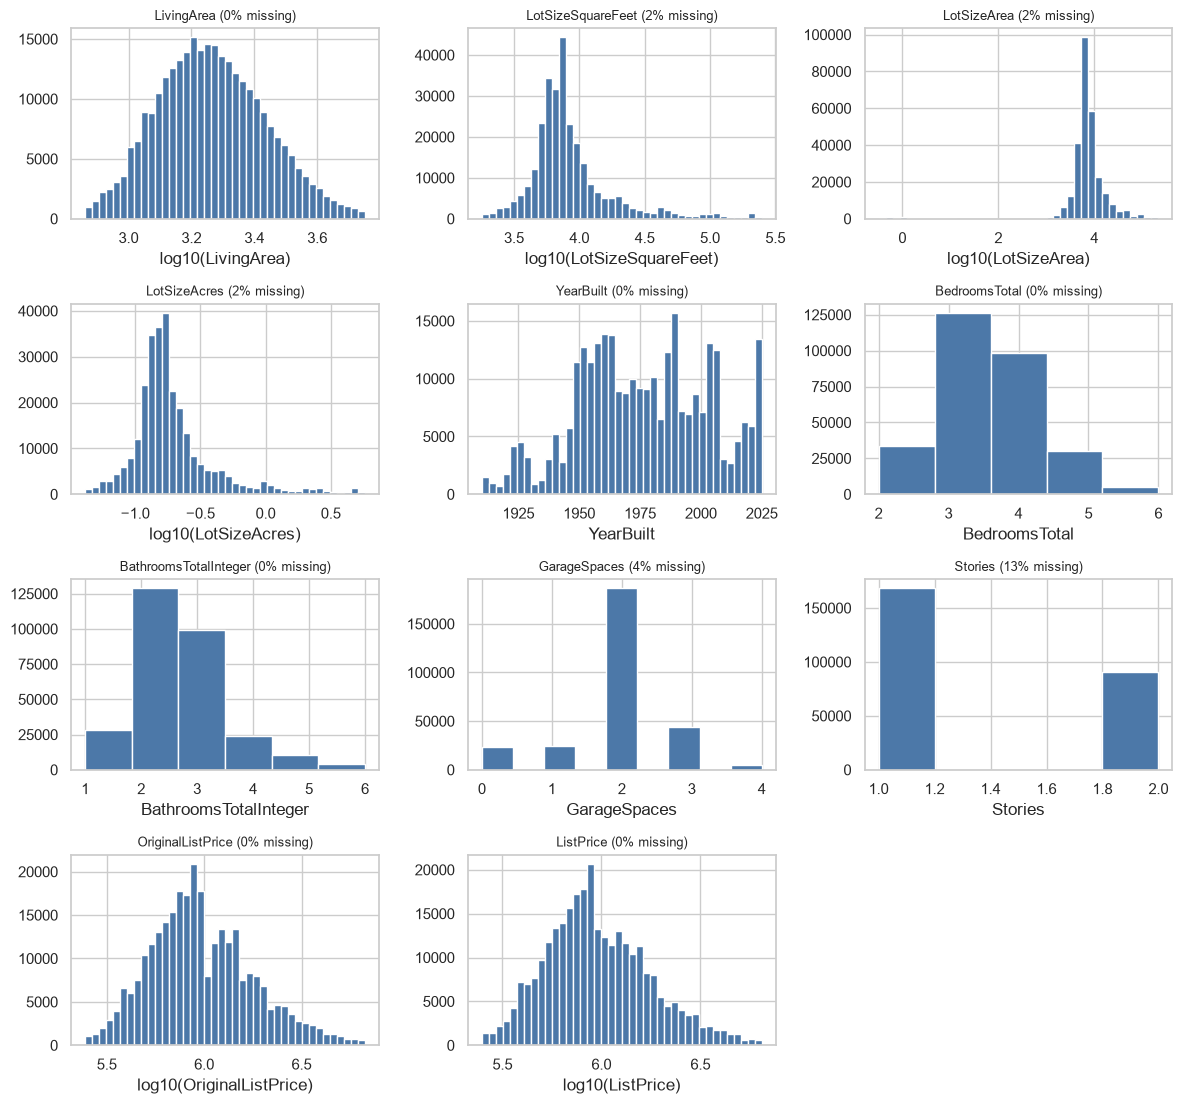

In [13]:
log_candidates = {
    "LivingArea", "LotSizeSquareFeet", "LotSizeArea", "LotSizeAcres",
    "AssociationFee", "TaxAnnualAmount", "OriginalListPrice", "ListPrice"
}
feature_candidates = [
    "LivingArea", "LotSizeSquareFeet", "LotSizeArea", "LotSizeAcres",
    "YearBuilt", "BedroomsTotal", "BathroomsTotalInteger", "GarageSpaces",
    "Stories", "OriginalListPrice", "ListPrice"
]
feature_cols = [
    c for c in feature_candidates
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]

n = len(feature_cols)
if n == 0:
    print("No selected numeric feature columns found.")
else:
    ncol = 3
    nrow = (n + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.8 * nrow), squeeze=False)
    for ax, col in zip(axes.ravel(), feature_cols):
        raw = df[col].dropna()
        shown = raw
        if len(shown):
            shown = shown[shown.between(shown.quantile(.01), shown.quantile(.99))]
        if col in log_candidates and len(shown) and (shown > 0).all():
            ax.hist(np.log10(shown), bins=40, color="#4c78a8")
            ax.set_xlabel(f"log10({col})")
        else:
            ax.hist(shown, bins=min(40, max(5, shown.nunique())) if len(shown) else 5, color="#4c78a8")
            ax.set_xlabel(col)
        ax.set_title(f"{col} ({df[col].isna().mean():.0%} missing)", fontsize=9)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

,False,True,missing
ViewYN,36.2,54.9,8.9
PoolPrivateYN,75.6,14.7,9.7
FireplaceYN,27.3,72.7,0.1
NewConstructionYN,89.2,3.6,7.2


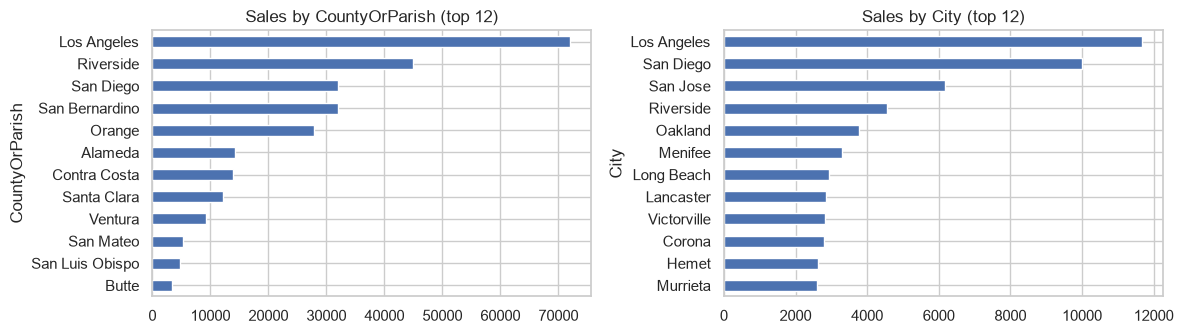

Unique City: 1096
Unique PostalCode: 3094
Unique CountyOrParish: 63


In [14]:
binary_candidates = [
    "ViewYN", "PoolPrivateYN", "FireplaceYN", "NewConstructionYN"
]
binary_cols = [c for c in binary_candidates if c in df.columns]
if binary_cols:
    share = pd.DataFrame({
        c: df[c].astype("object").where(df[c].notna(), "missing").astype(str)
             .value_counts(normalize=True)
        for c in binary_cols
    }).T
    display((share.fillna(0) * 100).round(1))
else:
    print("No selected binary/categorical flag columns found.")

geo_cols = [c for c in ["CountyOrParish", "City"] if c in df.columns]
if geo_cols:
    fig, axes = plt.subplots(1, len(geo_cols), figsize=(6 * len(geo_cols), 3.5), squeeze=False)
    for ax, col in zip(axes.ravel(), geo_cols):
        df[col].fillna("missing").astype(str).value_counts().head(12).sort_values().plot(
            kind="barh", ax=ax, title=f"Sales by {col} (top 12)"
        )
    plt.tight_layout()
    plt.show()

for col in ["City", "PostalCode", "CountyOrParish"]:
    if col in df.columns:
        print(f"Unique {col}: {df[col].nunique(dropna=True)}")

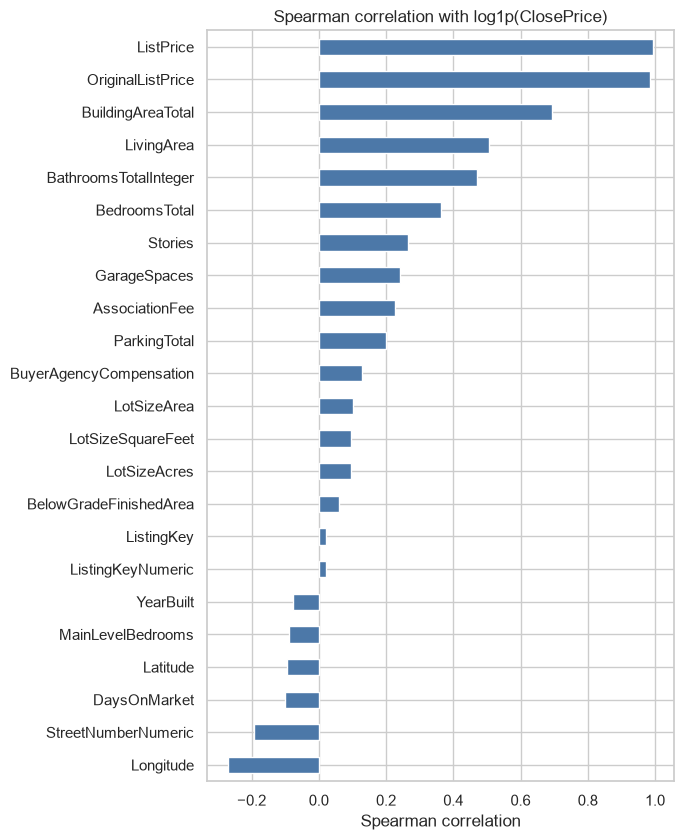

In [15]:
# Build the target series aligned to the same training rows.
corr_data = df.copy()
corr_data["_log_price"] = np.log1p(corr_data[TARGET].where(corr_data[TARGET] > 0))

numeric_corr_cols = [
    c for c in df.columns
    if c != TARGET and pd.api.types.is_numeric_dtype(df[c])
    and df[c].notna().sum() > 100
]
corr_y = {}
for col in numeric_corr_cols:
    pair = corr_data[[col, "_log_price"]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(pair) > 2 and pair[col].nunique() > 1:
        corr_y[col] = pair[col].corr(pair["_log_price"], method="spearman")

corr_y = pd.Series(corr_y).dropna().sort_values()
if len(corr_y):
    ax = corr_y.plot(
        kind="barh", figsize=(7, max(3, 0.32 * len(corr_y) + 1.2)),
        color="#4c78a8", title="Spearman correlation with log1p(ClosePrice)"
    )
    ax.set_xlabel("Spearman correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough valid numeric feature/target pairs for correlation.")

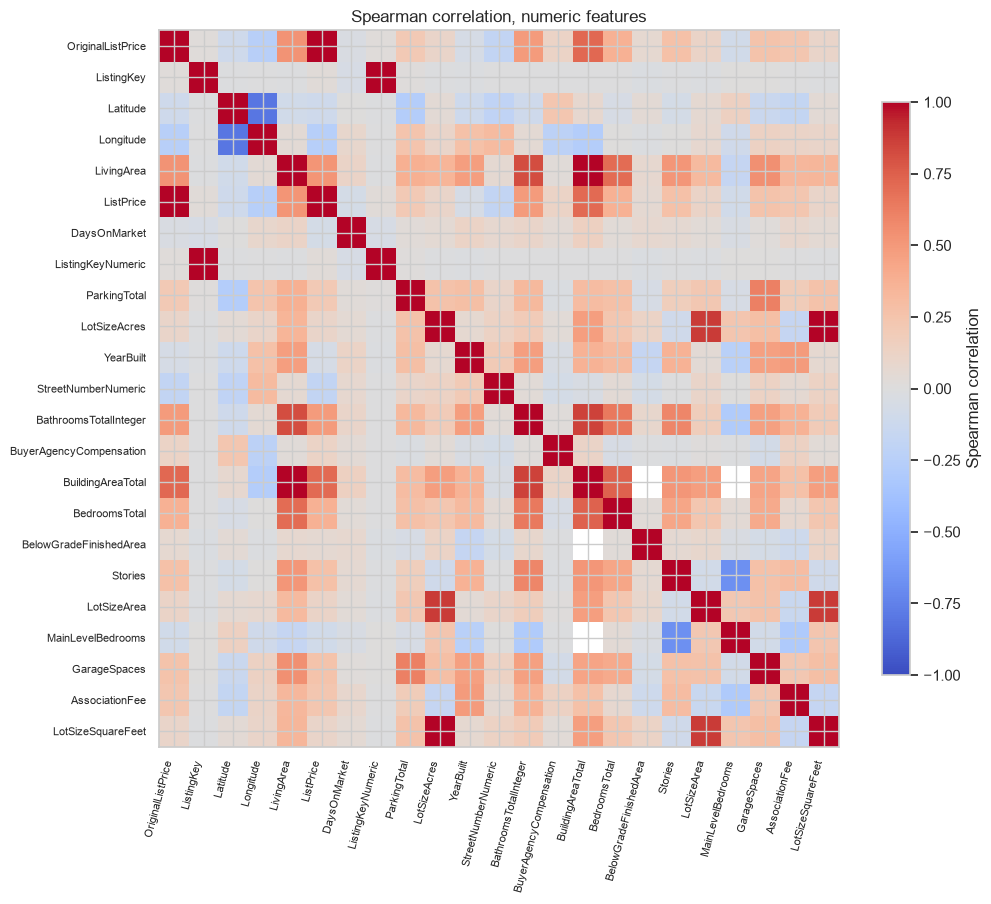

In [16]:
if numeric_corr_cols:
    cm = df[numeric_corr_cols].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(max(7.5, .45 * len(cm)), max(6, .4 * len(cm))))
    im = ax.imshow(cm, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(len(cm)))
    ax.set_xticklabels(cm.columns, rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(len(cm)))
    ax.set_yticklabels(cm.columns, fontsize=8)
    fig.colorbar(im, shrink=.8, label="Spearman correlation")
    ax.set_title("Spearman correlation, numeric features")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for correlation matrix.")

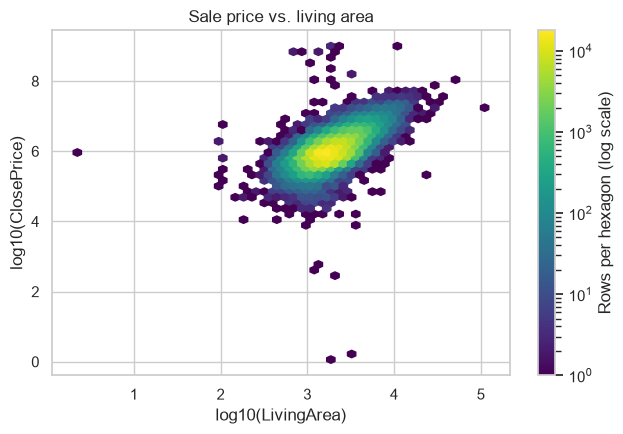

In [17]:
if "LivingArea" in df.columns:
    d = df[["LivingArea", TARGET]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d["LivingArea"] > 0) & (d[TARGET] > 0)]
    if not d.empty:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        hb = ax.hexbin(
            np.log10(d["LivingArea"]), np.log10(d[TARGET]),
            gridsize=50, bins="log", cmap="viridis", mincnt=1
        )
        ax.set_xlabel("log10(LivingArea)")
        ax.set_ylabel("log10(ClosePrice)")
        ax.set_title("Sale price vs. living area")
        fig.colorbar(hb, ax=ax, label="Rows per hexagon (log scale)")
        plt.tight_layout()
        plt.show()
    else:
        print("No positive finite LivingArea/ClosePrice pairs to plot.")
else:
    print("LivingArea is not present in the dataset.")

In [18]:
def group_median(data, col, target=TARGET, min_n=30):
    grouped = data.groupby(
        data[col].astype("object").where(data[col].notna(), "missing").astype(str)
    )[target].agg(n="count", median_price="median")
    return grouped.loc[grouped["n"] >= min_n].sort_values("median_price")

for col in ["BedroomsTotal", "BathroomsTotalInteger"] + binary_cols:
    if col in df.columns:
        print(f"\n{col}")
        display(group_median(df, col).round(0))


BedroomsTotal


,n,median_price
BedroomsTotal,,
1,1924,415500.0
0,173,550000.0
2,33594,649000.0
3,126258,820000.0
4,98660,1030000.0
5,30051,1400000.0
6,5110,1835500.0
8,280,1950000.0
10,42,1975000.0



BathroomsTotalInteger


,n,median_price
BathroomsTotalInteger,,
0.0,128,609000.0
1.0,28043,650000.0
missing,50,650000.0
2.0,128732,785000.0
3.0,98946,999000.0
4.0,24121,1595000.0
5.0,10461,2450000.0
6.0,4109,3480000.0
7.0,1452,4600000.0



ViewYN


...

,n,median_price
PoolPrivateYN,,
False,224746,820000.0
True,43720,1111000.0
missing,28756,1700000.0



FireplaceYN


,n,median_price
FireplaceYN,,
False,81086,712872.0
True,215942,1000000.0
missing,194,1447750.0



NewConstructionYN


,n,median_price
NewConstructionYN,,
True,10700,647990.0
False,264996,893322.0
missing,21526,995000.0


In [19]:
rows = []
exclude_missingness = {TARGET, "_log_price", "price_per_sqft"}
for col in df.columns:
    missing_mask = df[col].isna()
    if col in exclude_missingness:
        continue
    if missing_mask.mean() > .02 and missing_mask.sum() > 50 and (~missing_mask).sum() > 50:
        price_missing = df.loc[missing_mask, TARGET].dropna()
        price_present = df.loc[~missing_mask, TARGET].dropna()
        if len(price_missing) and len(price_present):
            median_missing = price_missing.median()
            median_present = price_present.median()
            ratio = median_missing / median_present if pd.notna(median_present) and median_present != 0 else np.nan
            rows.append((
                col, round(100 * missing_mask.mean(), 1),
                median_missing, median_present, ratio
            ))

miss_tab = pd.DataFrame(
    rows,
    columns=["column", "pct_missing", "median_price_if_missing",
             "median_price_if_present", "ratio"]
)
if not miss_tab.empty:
    display(miss_tab.sort_values("ratio", na_position="last").round(2))
else:
    print("No columns met the missingness-summary thresholds.")

,column,pct_missing,median_price_if_missing,median_price_if_present,ratio
2,WaterfrontYN,100.0,890000.0,1677500.0,0.53
17,BuildingAreaTotal,93.7,870000.0,1520000.0,0.57
10,ElementarySchool,86.3,850000.0,1297771.0,0.65
20,MiddleOrJuniorSchool,86.2,850000.0,1267500.0,0.67
24,LotSizeDimensions,93.9,875000.0,1300000.0,0.67
3,BasementYN,97.6,886000.0,1225000.0,0.72
22,HighSchool,82.1,850000.0,1175000.0,0.72
18,CoBuyerAgentFirstName,91.0,874000.0,1207500.0,0.72
13,SubdivisionName,65.4,825000.0,1037500.0,0.80
6,CoListAgentFirstName,77.2,860000.0,1049900.0,0.82


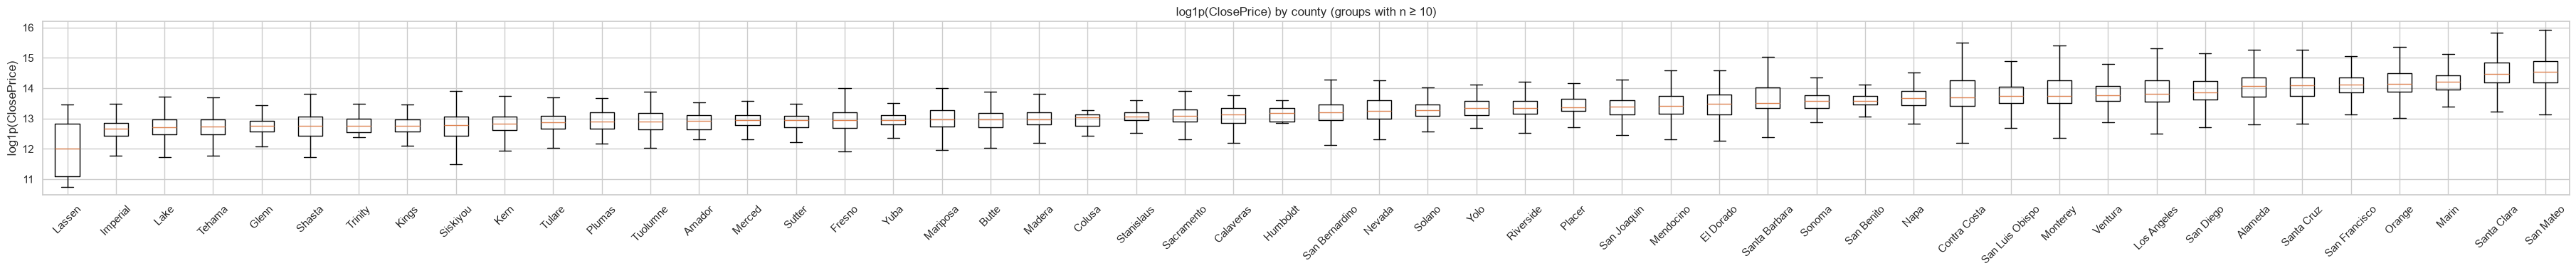

In [20]:
geo_col = "CountyOrParish"
if geo_col in df.columns:
    geo = df[[geo_col, TARGET]].dropna().copy()
    geo = geo[geo[TARGET] > 0]
    counts = geo[geo_col].value_counts()
    keep_geo = counts[counts >= 10].index
    geo = geo[geo[geo_col].isin(keep_geo)].copy()
    if not geo.empty:
        geo["log_price"] = np.log1p(geo[TARGET])
        order = geo.groupby(geo_col)["log_price"].median().sort_values().index
        data_for_plot = [geo.loc[geo[geo_col] == c, "log_price"].to_numpy() for c in order]
        fig, ax = plt.subplots(figsize=(max(8, .7 * len(order)), 4))
        ax.boxplot(data_for_plot, tick_labels=[str(c) for c in order], showfliers=False)
        ax.tick_params(axis="x", rotation=45)
        ax.set_title("log1p(ClosePrice) by county (groups with n ≥ 10)")
        ax.set_ylabel("log1p(ClosePrice)")
        plt.tight_layout()
        plt.show()
    else:
        print("No counties have at least 10 positive-price observations.")
else:
    print(f"{geo_col} is not present; skipping county plot.")

------------------------------------------------------------------------------------------------------------------------------------------------